# Cyclistic Bike-Share Analysis Case Study

## 1. Ask Phase

### Background
Cyclistic is a bike-share program in Chicago featuring more than 5,800 bicycles and 600 docking stations. The company offers two main pricing plans:
* **Casual Riders:** Customers who purchase single-ride or full-day passes.
* **Annual Members:** Customers who purchase annual memberships.

Financial analysts have determined that annual members are significantly more profitable than casual riders. The Director of Marketing, Lily Moreno, believes maximizing the number of annual memberships is key to future growth.

### Business Task
Analyze historical Cyclistic bike trip data to identify how annual members and casual riders use Cyclistic bikes differently. These data-driven insights will guide the marketing team in designing a targeted strategy to convert casual riders into annual members.

### Key Stakeholders
* **Lily Moreno:** Director of Marketing (project sponsor and manager).
* **Cyclistic Marketing Analytics Team:** Team responsible for data collection, analysis, and reporting.
* **Cyclistic Executive Team:** Detail-oriented decision-makers who will approve or reject the final marketing recommendations.

## 2. Prepare Phase

### Data Sources
The data used for this analysis is historical trip data provided by Motivate International Inc. under the Divvy bike-share data license. It covers the previous 12 months of operations and is organized into 12 monthly files (11 CSV files and 1 Excel file) containing trip details such as ride ID, bike type, start/end times, station names, and user type (`member_casual`).

### Data Credibility (ROCCC Framework)
* **Reliable:** The data is collected automatically through Cyclistic's tracking system, minimizing human error.
* **Original:** Provided directly by Motivate International Inc. as primary public trip data.
* **Comprehensive:** Contains millions of records covering all seasons, days of the week, and user categories.
* **Current:** Covers a recent 12-month period to accurately reflect current user behaviors.
* **Cited:** Properly licensed and made publicly available for analysis.

### Data Privacy & Limitations
To comply with data-privacy regulations, personally identifiable information (PII) such as rider names and credit card numbers has been stripped from the dataset. Consequently, we cannot track whether casual riders reside within the service area or if an individual casual rider has purchased multiple single passes.

In [1]:
import glob
import os
import pandas as pd

# Find all files in the input directory
all_files = sorted(glob.glob('/kaggle/input/**/*.*', recursive=True))

print(f'Total files found: {len(all_files)}')
for file_path in all_files:
  print(file_path)


Total files found: 12
/kaggle/input/datasets/mohammedmustafa648/cyclistic-uncleaned-data/22-04.csv
/kaggle/input/datasets/mohammedmustafa648/cyclistic-uncleaned-data/22-05..csv
/kaggle/input/datasets/mohammedmustafa648/cyclistic-uncleaned-data/22-06.csv
/kaggle/input/datasets/mohammedmustafa648/cyclistic-uncleaned-data/22-07.csv
/kaggle/input/datasets/mohammedmustafa648/cyclistic-uncleaned-data/22-08.csv
/kaggle/input/datasets/mohammedmustafa648/cyclistic-uncleaned-data/22-09.xlsx
/kaggle/input/datasets/mohammedmustafa648/cyclistic-uncleaned-data/22-10.csv
/kaggle/input/datasets/mohammedmustafa648/cyclistic-uncleaned-data/22-11.csv
/kaggle/input/datasets/mohammedmustafa648/cyclistic-uncleaned-data/22-12.csv
/kaggle/input/datasets/mohammedmustafa648/cyclistic-uncleaned-data/23-01.csv
/kaggle/input/datasets/mohammedmustafa648/cyclistic-uncleaned-data/23-02.csv
/kaggle/input/datasets/mohammedmustafa648/cyclistic-uncleaned-data/23-03.csv


In [2]:
import glob
import os
import pandas as pd

# 1. Find all files in the input directory
all_files = sorted(glob.glob('/kaggle/input/**/*.*', recursive=True))
print(f'Total files found: {len(all_files)}')

# 2. Read and merge all files (CSV and Excel)
dataframes_list = []

for file in all_files:
  if file.endswith('.csv'):
    print(f'Reading CSV: {os.path.basename(file)}')
    df_temp = pd.read_csv(file)
    dataframes_list.append(df_temp)
  elif file.endswith('.xlsx'):
    print(f'Reading Excel: {os.path.basename(file)}')
    df_temp = pd.read_excel(file)
    dataframes_list.append(df_temp)

# 3. Concatenate into a single dataframe
df_all = pd.concat(dataframes_list, ignore_index=True)

print('\n--- Merge Completed Successfully ---')
print(f'Total Rows: {df_all.shape[0]}')
print(f'Total Columns: {df_all.shape[1]}')

Total files found: 12
Reading CSV: 22-04.csv
Reading CSV: 22-05..csv
Reading CSV: 22-06.csv
Reading CSV: 22-07.csv
Reading CSV: 22-08.csv
Reading Excel: 22-09.xlsx
Reading CSV: 22-10.csv
Reading CSV: 22-11.csv
Reading CSV: 22-12.csv
Reading CSV: 23-01.csv
Reading CSV: 23-02.csv
Reading CSV: 23-03.csv

--- Merge Completed Successfully ---
Total Rows: 5803720
Total Columns: 13


## 3. Process Phase

### Tool Selection
To process and clean over 5 million rows of trip data across 12 monthly files, **Python** (utilizing the `pandas` and `glob` libraries within Kaggle Notebooks) was selected over spreadsheet tools like Excel or Google Sheets, which have row limitations and performance bottlenecks when handling large datasets. Python ensures high processing speed, reproducibility, and accuracy.

### Data Integrity & Cleaning Steps
Before analysis, the combined dataset (`df_all`) underwent a systematic cleaning and transformation workflow to ensure data integrity:
1. **Datetime Conversion:** Converted the `started_at` and `ended_at` columns from string text into standardized `datetime` objects to enable accurate time-based calculations.
2. **Feature Engineering:**
   * **`ride_length`:** Calculated the exact duration of each trip in minutes by subtracting `started_at` from `ended_at`.
   * **`day_of_week`:** Extracted the day name (Sunday through Saturday) from `started_at` to analyze weekly riding patterns.
   * **`hour` & `month`:** Extracted the start hour (`0–23`) and month name to uncover daily peak hours and seasonal trends.
3. **Filtering Anomalies & Errors:**
   * Removed rides with negative, zero, or extremely short durations (`ride_length <= 1` minute), which typically represent false starts, system errors, or users immediately re-docking a defective bike.
   * Filtered out extreme outliers exceeding 24 hours (`ride_length >= 1440` minutes), which likely indicate stolen/lost bikes or unclosed docking sessions.
4. **Deduplication:** Checked and removed any duplicate records based on the unique `ride_id` column to ensure every trip is counted only once.

### Verification of Clean Data
To verify that the dataset (`df_clean`) is clean and ready for analysis, summary statistics (`describe()`) were generated to confirm that all `ride_length` values fall strictly within the valid range (`> 1` minute and `< 1440` minutes), and row counts before and after filtering were documented to ensure transparency.

In [3]:
# Step 1: Convert start and end timestamps to datetime format
df_all['started_at'] = pd.to_datetime(df_all['started_at'])
df_all['ended_at'] = pd.to_datetime(df_all['ended_at'])

# Step 2: Create 'ride_length' (in minutes) and 'day_of_week'
df_all['ride_length'] = (
    df_all['ended_at'] - df_all['started_at']
).dt.total_seconds() / 60
df_all['day_of_week'] = df_all['started_at'].dt.day_name()
df_all['hour'] = df_all['started_at'].dt.hour
df_all['month'] = df_all['started_at'].dt.month_name()

# Step 3: Clean data (remove rides <= 1 min, >= 24 hours, and duplicate ride_ids)
df_clean = df_all[
    (df_all['ride_length'] > 1) & (df_all['ride_length'] < 1440)
].copy()
df_clean.drop_duplicates(subset=['ride_id'], inplace=True)

# Step 4: Verify that data is clean and ready for analysis
print(f'Total rows before cleaning: {len(df_all)}')
print(f'Total rows after cleaning:  {len(df_clean)}')
print(f'Total removed rows:         {len(df_all) - len(df_clean)}')
print('\n--- Summary Statistics for ride_length (Verification) ---')
print(df_clean['ride_length'].describe())

Total rows before cleaning: 5803720
Total rows after cleaning:  5659024
Total removed rows:         144696

--- Summary Statistics for ride_length (Verification) ---
count    5.659024e+06
mean     1.627117e+01
std      2.916832e+01
min      1.016667e+00
25%      6.000000e+00
50%      1.025000e+01
75%      1.825000e+01
max      1.439933e+03
Name: ride_length, dtype: float64


## 4. Analyze Phase

### Data Organization & Formatting
To prepare for statistical aggregation, the cleaned dataset (`df_clean`) was organized and formatted by converting `day_of_week` and `month` into ordered categorical variables (`Sunday`–`Saturday` and `January`–`December`). This ensured chronological accuracy rather than alphabetical sorting when evaluating temporal patterns.

### Key Analytical Findings & Trends
Using Python (`pandas` `groupby` and `agg` functions), the data was aggregated to compare annual members (`member`) against casual riders (`casual`):
1. **Ride Volume vs. Ride Duration:** While annual members account for the majority of total rides, casual riders consistently take significantly longer trips on average (nearly double the duration of members).
2. **Weekly Riding Patterns:**
   * **Casual Riders:** Ride volume surges dramatically on weekends (**Saturday and Sunday**), indicating leisure, sightseeing, and recreational usage.
   * **Annual Members:** Ride frequency peaks during weekdays (**Tuesday through Thursday**), with lower activity on weekends, reflecting routine commuting habits.
3. **Seasonal & Bike Preferences:** Both user groups exhibit strong seasonality, with ridership peaking during warmer summer months (**June–August**) and declining sharply in winter. Additionally, casual riders show a higher preference for electric bikes and docked bikes compared to members.

### Answering the Business Question
These behavioral differences confirm that annual members use Cyclistic primarily for **practical, daily commuting**, whereas casual riders use the service for **leisure and weekend recreation**. Marketing strategies aimed at converting casual riders should therefore highlight weekend cost savings, flexible leisure perks, and seasonal membership benefits.

In [4]:
# 1. Overall Descriptive Analysis on ride_length & mode of day_of_week
print('--- 1. Overall Ride Length Statistics (Minutes) ---')
print(f"Mean ride length:   {df_clean['ride_length'].mean():.2f} mins")
print(f"Median ride length: {df_clean['ride_length'].median():.2f} mins")
print(f"Max ride length:    {df_clean['ride_length'].max():.2f} mins")
print(f"Min ride length:    {df_clean['ride_length'].min():.2f} mins")
print(f"Most popular day (Mode): {df_clean['day_of_week'].mode()[0]}")

# 2. Compare Members vs. Casual Riders (Total Rides, Mean & Median Ride Length)
print('\n--- 2. Summary by User Type (member vs. casual) ---')
user_summary = (
    df_clean.groupby('member_casual')['ride_length']
    .agg(total_rides='count', mean_duration='mean', median_duration='median')
    .reset_index()
)
display(user_summary)

# 3. Analyze Rides & Average Duration by Day of Week (Ordered Sunday to Saturday)
print('\n--- 3. Rides & Average Duration by Day of Week ---')
days_order = [
    'Sunday',
    'Monday',
    'Tuesday',
    'Wednesday',
    'Thursday',
    'Friday',
    'Saturday',
]
df_clean['day_of_week'] = pd.Categorical(
    df_clean['day_of_week'], categories=days_order, ordered=True
)

weekly_summary = (
    df_clean.groupby(['member_casual', 'day_of_week'], observed=False)[
        'ride_length'
    ]
    .agg(total_rides='count', avg_duration='mean')
    .reset_index()
)
display(weekly_summary)

# 4. Analyze Monthly Trends & Bike Type Preferences
print('\n--- 4. Monthly Ride Counts by User Type ---')
months_order = [
    'January',
    'February',
    'March',
    'April',
    'May',
    'June',
    'July',
    'August',
    'September',
    'October',
    'November',
    'December',
]
df_clean['month'] = pd.Categorical(
    df_clean['month'], categories=months_order, ordered=True
)

monthly_summary = (
    df_clean.groupby(['member_casual', 'month'], observed=False)['ride_id']
    .count()
    .reset_index(name='total_rides')
)
display(monthly_summary)

print('\n--- 5. Bike Type Preference by User Type ---')
bike_summary = (
    df_clean.groupby(['member_casual', 'rideable_type'])['ride_id']
    .count()
    .reset_index(name='total_rides')
)
display(bike_summary)

# 6. Export Summary File for Further Visualization (Deliverable Step 5)
weekly_summary.to_csv('cyclistic_weekly_summary.csv', index=False)
print("\nSummary file 'cyclistic_weekly_summary.csv' exported successfully!")

--- 1. Overall Ride Length Statistics (Minutes) ---
Mean ride length:   16.27 mins
Median ride length: 10.25 mins
Max ride length:    1439.93 mins
Min ride length:    1.02 mins
Most popular day (Mode): Saturday

--- 2. Summary by User Type (member vs. casual) ---


,member_casual,total_rides,mean_duration,median_duration
0,casual,2280689,21.876700,13.00
1,member,3378335,12.486917,8.95



--- 3. Rides & Average Duration by Day of Week ---


,member_casual,day_of_week,total_rides,avg_duration
0,casual,Sunday,379899,25.097336
1,casual,Monday,269101,22.076276
2,casual,Tuesday,264785,19.621852
3,casual,Wednesday,270089,18.623816
4,casual,Thursday,304233,19.573903
5,casual,Friday,332595,20.687260
6,casual,Saturday,459987,24.691095
7,member,Sunday,387569,13.833610
8,member,Monday,472565,11.987806
9,member,Tuesday,530874,11.886345



--- 4. Monthly Ride Counts by User Type ---


,member_casual,month,total_rides
0,casual,January,38738
1,casual,February,41725
2,casual,March,60139
3,casual,April,123781
4,casual,May,274496
5,casual,June,360984
6,casual,July,396776
7,casual,August,350444
8,casual,September,287942
9,casual,October,203835



--- 5. Bike Type Preference by User Type ---


,member_casual,rideable_type,total_rides
0,casual,classic_bike,873830
1,casual,docked_bike,170172
2,casual,electric_bike,1236687
3,member,classic_bike,1721105
4,member,electric_bike,1657230



Summary file 'cyclistic_weekly_summary.csv' exported successfully!


## 5. Share Phase

### Audience & Communication Strategy
The primary audience for this analysis is **Lily Moreno** (Director of Marketing) and the **Cyclistic Executive Team**. Because executive stakeholders require clear, actionable insights rather than raw data tables, **Python (`matplotlib` and `seaborn`)** was used to create clean, high-contrast visualizations that tell a cohesive story about user behavior.

### Accessibility & Visual Design Principles
* **Colorblind-Friendly Palette:** A high-contrast palette (**Deep Blue `#1f77b4`** for Annual Members vs. **Vibrant Orange `#ff7f0e`** for Casual Riders) was consistently applied across all charts to ensure immediate visual distinction and accessibility.
* **Clear Hierarchy:** Every visualization includes a descriptive action title, clear axis labels, formatted tick numbers (in thousands/millions), and clean gridlines to minimize visual clutter.

### Key Visual Takeaways
1. **Weekday Commuting vs. Weekend Leisure:** Annual members dominate weekday ridership, whereas casual riders surge on Saturdays and Sundays.
2. **Rush-Hour Peaks:** Hourly trends reveal sharp spikes for members at **8:00 AM** and **5:00 PM** (commuting hours), while casual ridership builds steadily throughout the afternoon.
3. **Trip Duration Contrast:** Casual riders consistently ride nearly twice as long per trip as annual members across every single day of the week.
4. **Seasonality:** Both groups peak during the warm summer months (June–August), presenting a prime seasonal window for targeted marketing campaigns.

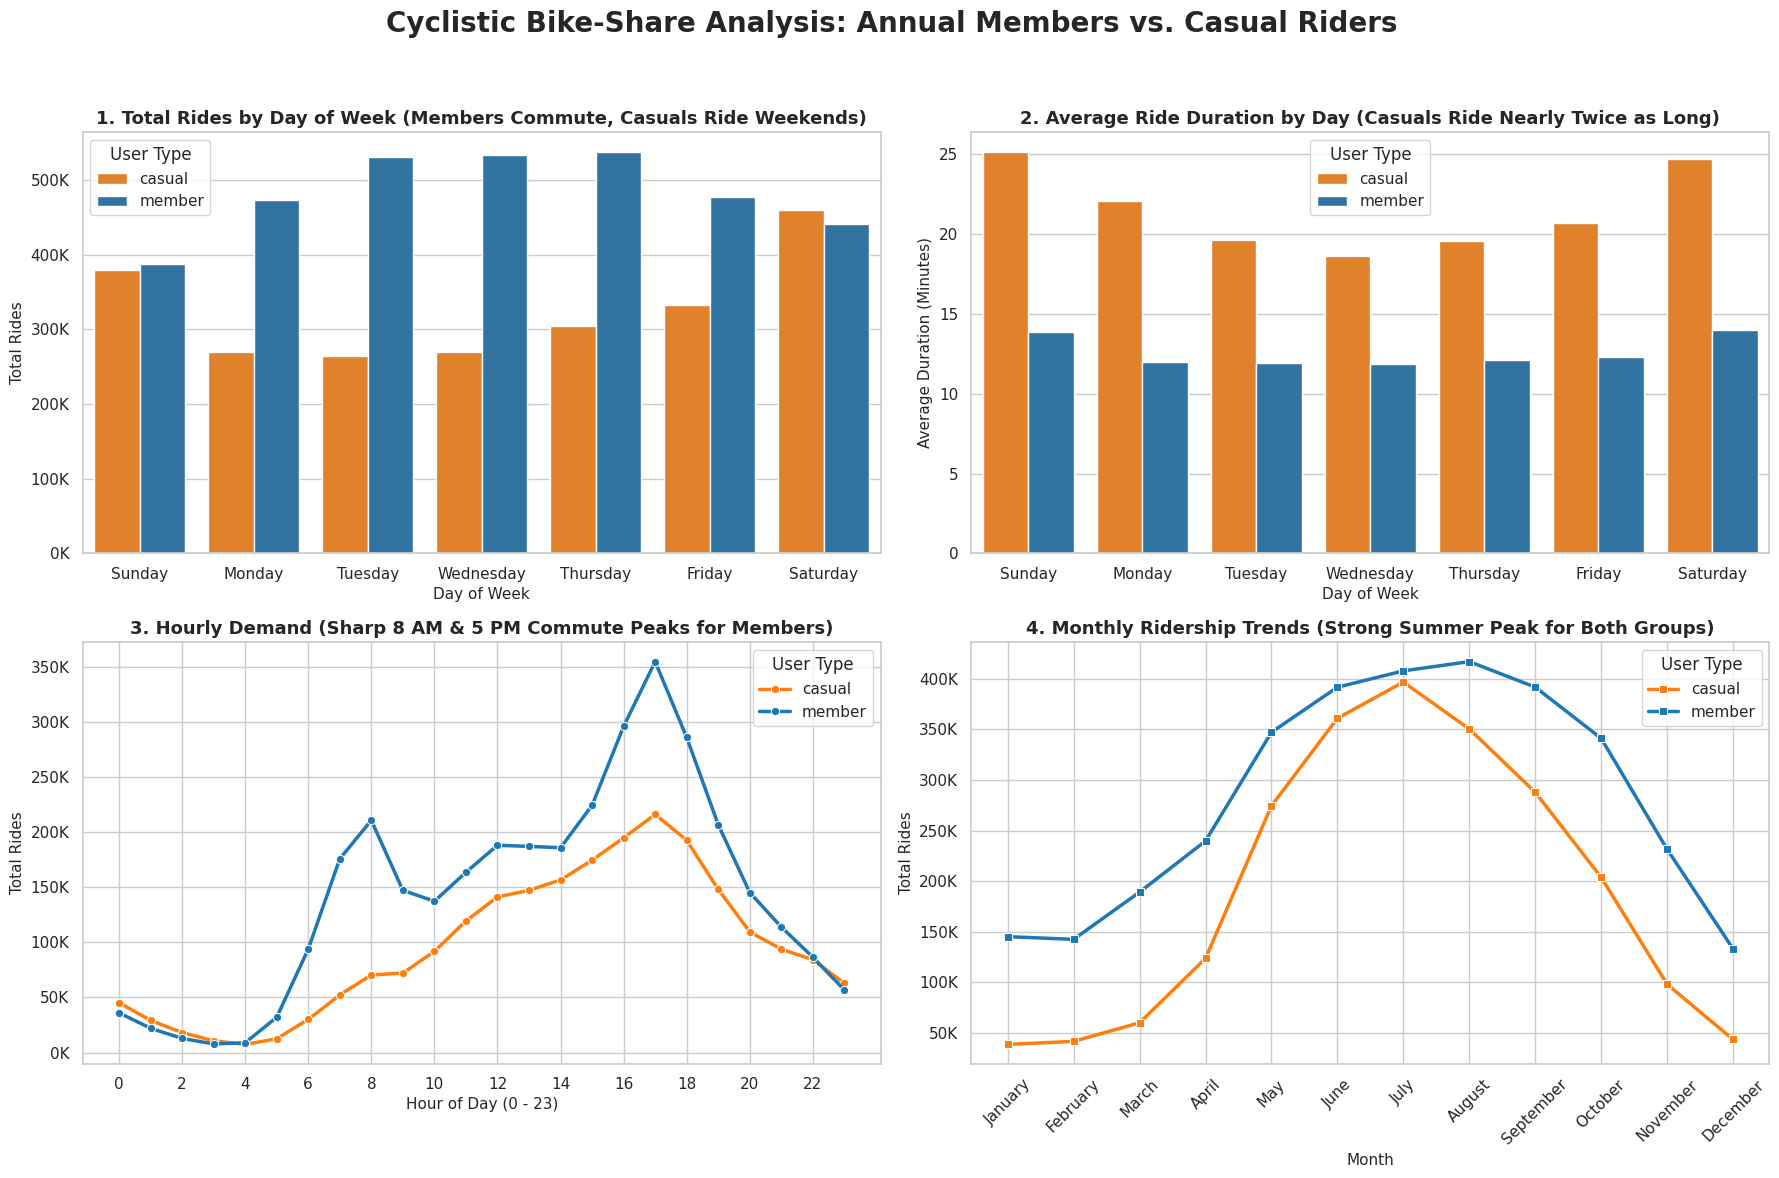

In [5]:
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns

# Set global visual style and accessible color palette
sns.set_theme(style='whitegrid')
palette = {'member': '#1f77b4', 'casual': '#ff7f0e'}

# Create a 2x2 dashboard figure for clean executive presentation
fig, axes = plt.subplots(2, 2, figsize=(18, 12))
fig.suptitle(
    'Cyclistic Bike-Share Analysis: Annual Members vs. Casual Riders',
    fontsize=20,
    fontweight='bold',
    y=0.98,
)

# --- Chart 1: Total Rides by Day of Week ---
sns.barplot(
    data=weekly_summary,
    x='day_of_week',
    y='total_rides',
    hue='member_casual',
    palette=palette,
    ax=axes[0, 0],
)
axes[0, 0].set_title(
    '1. Total Rides by Day of Week (Members Commute, Casuals Ride Weekends)',
    fontsize=13,
    fontweight='bold',
)
axes[0, 0].set_xlabel('Day of Week', fontsize=11)
axes[0, 0].set_ylabel('Total Rides', fontsize=11)
axes[0, 0].yaxis.set_major_formatter(
    ticker.FuncFormatter(lambda x, pos: f'{int(x/1000):,}K')
)
axes[0, 0].legend(title='User Type')

# --- Chart 2: Average Ride Duration by Day of Week ---
sns.barplot(
    data=weekly_summary,
    x='day_of_week',
    y='avg_duration',
    hue='member_casual',
    palette=palette,
    ax=axes[0, 1],
)
axes[0, 1].set_title(
    '2. Average Ride Duration by Day (Casuals Ride Nearly Twice as Long)',
    fontsize=13,
    fontweight='bold',
)
axes[0, 1].set_xlabel('Day of Week', fontsize=11)
axes[0, 1].set_ylabel('Average Duration (Minutes)', fontsize=11)
axes[0, 1].legend(title='User Type')

# --- Chart 3: Hourly Riding Trends (24-Hour Cycle) ---
hourly_summary = (
    df_clean.groupby(['member_casual', 'hour'])['ride_id']
    .agg(total_rides='count')
    .reset_index()
)
sns.lineplot(
    data=hourly_summary,
    x='hour',
    y='total_rides',
    hue='member_casual',
    palette=palette,
    linewidth=2.5,
    marker='o',
    ax=axes[1, 0],
)
axes[1, 0].set_title(
    '3. Hourly Demand (Sharp 8 AM & 5 PM Commute Peaks for Members)',
    fontsize=13,
    fontweight='bold',
)
axes[1, 0].set_xlabel('Hour of Day (0 - 23)', fontsize=11)
axes[1, 0].set_ylabel('Total Rides', fontsize=11)
axes[1, 0].set_xticks(range(0, 24, 2))
axes[1, 0].yaxis.set_major_formatter(
    ticker.FuncFormatter(lambda x, pos: f'{int(x/1000):,}K')
)
axes[1, 0].legend(title='User Type')

# --- Chart 4: Monthly Seasonality Trends ---
sns.lineplot(
    data=monthly_summary,
    x='month',
    y='total_rides',
    hue='member_casual',
    palette=palette,
    linewidth=2.5,
    marker='s',
    ax=axes[1, 1],
)
axes[1, 1].set_title(
    '4. Monthly Ridership Trends (Strong Summer Peak for Both Groups)',
    fontsize=13,
    fontweight='bold',
)
axes[1, 1].set_xlabel('Month', fontsize=11)
axes[1, 1].set_ylabel('Total Rides', fontsize=11)
axes[1, 1].tick_params(axis='x', rotation=45)
axes[1, 1].yaxis.set_major_formatter(
    ticker.FuncFormatter(lambda x, pos: f'{int(x/1000):,}K')
)
axes[1, 1].legend(title='User Type')

# Adjust layout and save high-resolution image for portfolio/slides
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.savefig('cyclistic_executive_dashboard.png', dpi=300)
plt.show()

## 6. Act Phase

### Final Conclusion
The analysis of over 5 million historical rides clearly reveals two distinct user personas:
* **Annual Members (`member`)** rely on Cyclistic as a dependable, daily commuting tool—evidenced by high weekday ride volume and sharp usage spikes at **8:00 AM** and **5:00 PM**.
* **Casual Riders (`casual`)** use Cyclistic primarily for leisure, tourism, and weekend recreation—evidenced by surging demand on **Saturdays and Sundays**, peak afternoon riding, and average trip durations nearly **double** those of annual members.

### Top 3 Strategic Recommendations
To convert casual riders into profitable annual members, the marketing team should execute the following data-driven strategies:

1. **Introduce a Flexible "Weekend & Leisure" Membership Tier:**
   * **Insight:** Casual ridership peaks heavily on weekends and involves significantly longer trip durations.
   * **Action:** Launch a targeted weekend-focused membership option or extend the complimentary ride-time limit per trip for annual members (e.g., 45–60 minutes instead of 30 minutes) to directly appeal to recreational riders who currently pay extra per-minute fees.
2. **Launch High-Impact Seasonal Campaigns (May–August):**
   * **Insight:** Casual ridership experiences dramatic seasonal growth during warm summer months.
   * **Action:** Concentrate digital ad spend and on-station promotional signage in late spring (**May–June**), offering limited-time summer conversion incentives (such as discounted first-year rates or bonus guest passes for friends and family).
3. **Implement Personalized In-App "Savings Alerts" & E-Bike Perks:**
   * **Insight:** Casual riders take long trips and show strong adoption of electric bikes.
   * **Action:** Trigger automated in-app notifications immediately after a casual rider completes a long trip or unlocks an electric bike, displaying an exact side-by-side cost comparison showing how much money an annual membership would have saved them on that ride.

### Next Steps & Future Data Collection
To further refine marketing targeting, Cyclistic should consider collecting optional rider survey data (e.g., trip purpose and local residency status) and tracking conversion rates across each promotional channel using unique referral codes.